# Traditional Machine Learning Model

## 1. Objective

The objective of this notebook is to develop a traditional machine learning baseline using **Logistic Regression** for student academic performance prediction.

The model classifies students into three performance categories:

- **Low:** Final grade 0–9
- **Average:** Final grade 10–13
- **Good:** Final grade 14–20

### Why Logistic Regression?

Logistic Regression is a simple and interpretable classification algorithm that can be extended to multiclass classification.

We use it as a baseline to evaluate whether a more complex Deep Neural Network provides better predictive performance.

### Fair Model Comparison

To ensure a fair comparison, both models will use:

- The same dataset and target categories
- The same input features, excluding `G1`, `G2` and `G3`
- The same training and validation splits
- The same numerical scaling and categorical encoding approach
- The same evaluation metrics

The final test set will remain reserved until model selection is complete.

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    recall_score
)
df = pd.read_csv("../data/student-por.csv", sep=";")

print("Dataset shape:", df.shape)
display(df.head())
def categorize_performance(grade):
    if grade < 10:
        return "Low"
    elif grade < 14:
        return "Average"
    else:
        return "Good"

df["performance_category"] = df["G3"].apply(categorize_performance)

print(df["performance_category"].value_counts())
X = df.drop(
    columns=["G1", "G2", "G3", "performance_category"]
)

y = df["performance_category"]

print("Features:", X.shape)
print("Target:", y.shape)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training pool:", X_train.shape)
print("Testing:", X_test.shape)

X_train_final, X_val, y_train_final, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

print("Training:", X_train_final.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Dataset shape: (649, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13


performance_category
Average    355
Good       194
Low        100
Name: count, dtype: int64
Features: (649, 30)
Target: (649,)
Training pool: (519, 30)
Testing: (130, 30)
Training: (415, 30)
Validation: (104, 30)
Testing: (130, 30)


In [15]:
numerical_features = X_train_final.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train_final.select_dtypes(
    include=["object", "category"]
).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

X_train_processed = preprocessor.fit_transform(X_train_final)
X_val_processed = preprocessor.transform(X_val)

print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))
print("Training processed:", X_train_processed.shape)
print("Validation processed:", X_val_processed.shape)

label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train_final)
y_val_encoded = label_encoder.transform(y_val)

print("Class mapping:")

for index, category in enumerate(label_encoder.classes_):
    print(index, "->", category)

Numerical features: 13
Categorical features: 17
Training processed: (415, 56)
Validation processed: (104, 56)
Class mapping:
0 -> Average
1 -> Good
2 -> Low


Logistic Regression Model

Logistic Regression is used as a traditional machine learning baseline.

We configure:

- max_iter=1000 to allow sufficient optimization iterations
- class_weight="balanced" to account for class imbalance
- random_state=42 for reproducibility

The model uses the same processed training data as the DNN.

In [16]:
lr_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

lr_model.fit(
    X_train_processed,
    y_train_encoded
)

print("Logistic Regression training completed.")

Logistic Regression training completed.


 Model Evaluation

We evaluate the model using:

- Accuracy
- Precision
- Recall
- F1-score
- Macro F1-score

Special attention is given to Low-class recall because
identifying academically at-risk students is an important
project objective.

In [17]:
y_val_pred = lr_model.predict(X_val_processed)

lr_accuracy = accuracy_score(y_val_encoded, y_val_pred)

lr_macro_f1 = f1_score(
    y_val_encoded,
    y_val_pred,
    average="macro",
    zero_division=0
)

low_index = int(label_encoder.transform(["Low"])[0])

lr_low_recall = recall_score(
    y_val_encoded,
    y_val_pred,
    labels=[low_index],
    average="macro",
    zero_division=0
)

print(f"Validation Accuracy: {lr_accuracy:.2%}")
print(f"Macro F1-score: {lr_macro_f1:.2%}")
print(f"Low-Class Recall: {lr_low_recall:.2%}")

print("\nClassification Report:\n")

print(
    classification_report(
        y_val_encoded,
        y_val_pred,
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

Validation Accuracy: 55.77%
Macro F1-score: 53.20%
Low-Class Recall: 50.00%

Classification Report:

              precision    recall  f1-score   support

     Average       0.70      0.49      0.58        57
        Good       0.56      0.71      0.63        31
         Low       0.32      0.50      0.39        16

    accuracy                           0.56       104
   macro avg       0.53      0.57      0.53       104
weighted avg       0.60      0.56      0.56       104



 Confusion Matrix

A confusion matrix shows the number of correct and incorrect
predictions for each performance category.

It helps identify which classes are being confused with others.

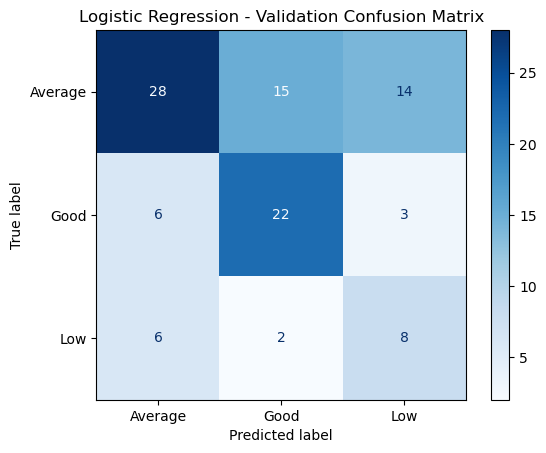

In [18]:
cm = confusion_matrix(
    y_val_encoded,
    y_val_pred
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=label_encoder.classes_
)

disp.plot(cmap="Blues", values_format="d")

plt.title("Logistic Regression - Validation Confusion Matrix")
plt.show()

DNN vs Logistic Regression Comparison

We compare Logistic Regression against our selected DNN using
the same validation dataset and evaluation metrics.

The DNN uses learning rate 0.001, dropout 0.2, and Early Stopping.

The comparison focuses on validation accuracy, macro F1-score,
and Low-class recall.

In [19]:
comparison_df = pd.DataFrame({
    "Model": [
        "Deep Neural Network",
        "Logistic Regression"
    ],
    "Validation Accuracy": [
        0.5865,
        lr_accuracy
    ],
    "Macro F1": [
        0.5523,
        lr_macro_f1
    ],
    "Low Recall": [
        0.4375,
        lr_low_recall
    ]
})

display(
    comparison_df.style.format({
        "Validation Accuracy": "{:.2%}",
        "Macro F1": "{:.2%}",
        "Low Recall": "{:.2%}"
    })
)

,Model,Validation Accuracy,Macro F1,Low Recall
0,Deep Neural Network,58.65%,55.23%,43.75%
1,Logistic Regression,55.77%,53.20%,50.00%


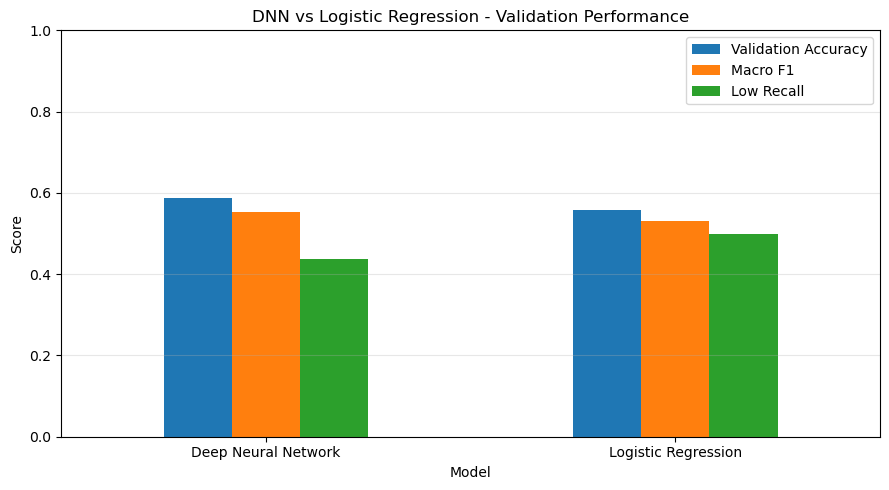

In [20]:
comparison_df.set_index("Model")[
    ["Validation Accuracy", "Macro F1", "Low Recall"]
].plot(
    kind="bar",
    figsize=(9, 5),
    rot=0
)

plt.title("DNN vs Logistic Regression - Validation Performance")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()